## Building a Precision-Based Spam Email Classifier : Baseline to Deployment

---

#### Overview

• The dataset I used for this small project is (https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv), it contains **5,572** rows, **2 columns (label and message)**. The label is separated via *Spam*, which are email that are verified as spam. *Ham*, which are emails that are legitimate. 


• For this model, I tested the models **LogisticRegression, Decision Tree, and Random Forests**. Specifically tuned for the highest *Precision* score. The winning model is **LogisticRegression**. At a threshold of *0.75*, its **Precision score peaked at 95.04%**, the **Recall score at 89.33%**, **F1-score (due to the dataset being unbalanced) at 92.1%** for spam emails. The number of legitimate emails predicted as spam (false positive) sits at 7, while the number of spam emails predicted as legitimate is at 16. These metrics are taken from the test set.

---

#### 1. Why Precision over Recall in Spam Filtering?

• To briefly explain Precision, it is the raising of the threshold score for a prediction to be considered as a target class. We want to be strict with making sure that an input x is Spam in order to avoid sending a legitimate email—an important one at that—into the spam folders, predicted incorrectly as spam. Thus preventing a potential catastrophic miss.

• However this comes with a tradeoff, being more strict with making sure an email is Spam before sending it into the Spam folder results to more Spam emails ending up unnoticed by the model. However, this is a smaller price to pay than incorrectly sending away a legitimate email. Hence why I reduced my Recall score in order to raise my Precision score in the threshold tuning.

In [20]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import plotly.express as px
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, precision_score, recall_score, f1_score, PrecisionRecallDisplay, ConfusionMatrixDisplay
from sklearn.model_selection import FixedThresholdClassifier

In [2]:
url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"
df = pd.read_csv(url, sep='\t', header=None, names=['label', 'message'])
print(df.head())
print(df['label'].value_counts())

  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
label
ham     4825
spam     747
Name: count, dtype: int64


In [3]:
X = df['message']
y = df['label']

y = df['label'].map({
    'spam': 1,
    'ham': 0
})

In [4]:

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size = 0.4,
    random_state = 42,
    stratify=y
    )

X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp,
    test_size = 0.5,
    random_state = 42,
    stratify=y_temp
)

#### 2. Text Preprocessing & Vectorizer Bottleneck

• Since the features in the model are text form, it is imperative that I use a word vectorizer in order to build a model from the dataset in the first place. I selected TfidfVectorizer as my word processor, ensuring that it doesn't just count how frequent a word appears in the document, but to scale and add weights upon the words accordingly. 

• I encapsulated the preprocessors into a Pipeline to cleanly format and test out different hyperparameters during model training.

In [5]:
param_grid_logistic = {
    'vectorizer_log__max_features' : [1500, 2500, 3000, None],
    'vectorizer_log__ngram_range' : [(1,1), (1,2), (1,3)],
    'vectorizer_log__min_df': [1, 2, 3],
    'grid_log__C': [0.1, 1.0, 10.0]
}

grid_logistic = Pipeline([
    ('vectorizer_log', TfidfVectorizer(
        lowercase=True,
        stop_words='english',
        sublinear_tf=True
    )),

    ('grid_log', LogisticRegression(
        class_weight = 'balanced',
        max_iter = 1000,
        random_state = 42
    ))
])

grid_search_log = GridSearchCV(
    estimator = grid_logistic,
    param_grid = param_grid_logistic,
    cv = 5,
    scoring = 'f1',
    n_jobs = 1,
    verbose = 1
)

grid_search_log.fit(X_train, y_train)
print("Best Hyperparameters:")
for param, val in grid_search_log.best_params_.items():
    print(f"  {param}: {val}")
print(f"\nBest Cross-Validation F1 Score: {grid_search_log.best_score_*100:.4f}%")

Fitting 5 folds for each of 108 candidates, totalling 540 fits
Best Hyperparameters:
  grid_log__C: 10.0
  vectorizer_log__max_features: 3000
  vectorizer_log__min_df: 2
  vectorizer_log__ngram_range: (1, 3)

Best Cross-Validation F1 Score: 93.7730%


In [6]:
param_grid_tree = {
    'vectorizer_tree__max_features' : [1500, 2500, 3000, None],
    'vectorizer_tree__ngram_range' : [(1,1), (1,2), (1,3)],
    'vectorizer_tree__min_df': [1, 2, 3],
    'grid_tree__max_depth': [10, 15, 20, 25],
    'grid_tree__min_samples_leaf': [1, 2, 5],
    'grid_tree__min_samples_split': [2, 10]
}

grid_tree = Pipeline([
    ('vectorizer_tree', TfidfVectorizer(
        lowercase=True,
        stop_words='english',
        sublinear_tf=True
    )),

    ('grid_tree', DecisionTreeClassifier(
        random_state=42,
        class_weight = 'balanced',
        ))
])


grid_search_tree = GridSearchCV(
    estimator = grid_tree,
    param_grid = param_grid_tree,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose = 1
    )

grid_search_tree.fit(X_train, y_train)
print("Best Hyperparameters:")
for param, val in grid_search_tree.best_params_.items():
    print(f"  {param}: {val}")
print(f"\nBest Cross-Validation F1 Score: {grid_search_tree.best_score_*100:.4f}%")

Fitting 5 folds for each of 864 candidates, totalling 4320 fits
Best Hyperparameters:
  grid_tree__max_depth: 20
  grid_tree__min_samples_leaf: 1
  grid_tree__min_samples_split: 2
  vectorizer_tree__max_features: None
  vectorizer_tree__min_df: 2
  vectorizer_tree__ngram_range: (1, 3)

Best Cross-Validation F1 Score: 86.4851%


In [7]:
logistic_pipeline = Pipeline([
    ('vectorizer', TfidfVectorizer(
        lowercase = True,
        stop_words = 'english',
        ngram_range = (1, 3),
        min_df = 2, 
        sublinear_tf = True,
        max_features = 3000  
        )),
        
    ('logistic_classifier', LogisticRegression(
        C = 10,
        random_state= 42,
        class_weight='balanced',
        max_iter = 1000,
    ))
])

tree_pipeline = Pipeline([
    ('vectorizer', TfidfVectorizer(
        lowercase = True,
        stop_words = 'english',
        ngram_range = (1, 3),
        min_df = 2,
        sublinear_tf = True,
        max_features = None 
    )),

    ('tree_classifier', DecisionTreeClassifier(
        random_state = 42,
        class_weight = 'balanced',
        max_depth = 20,
        min_samples_leaf= 1,
        min_samples_split = 2
    ))
])


#### 3. Model Showdown: Decision Tree vs. Logistic Regression vs. Random Forest

• To start with the model selection, I placed LogisticRegression up with a single Decision Tree to see the baseline comparison. To handle the hyperparameter tuning, I created multiple GridSearchCVs to get the hyperparameters for the best accuracy for LogisticRegression and Decision Tree (and later on Random Forests).

• **LogisticRegression came up with a baseline of 92.83% F1-score and 94.44% Precision** for Spam emails, while **Decision Tree came up with a baseline of 82.89% F1-score and 81.29% Precision** for Spam emails.

• After training and optimizing a Random Forest model, it came up with a **91.17% F1-score** and a **Precision score of 96.27%**. Narrowly beating LogisticRegression's 94.44% Precision score.



In [8]:
logistic_pipeline.fit(X_train, y_train)
tree_pipeline.fit(X_train, y_train)

log_predictions = logistic_pipeline.predict(X_valid)
tree_predictions = tree_pipeline.predict(X_valid)

print("=== Logistic Evaluation ===")
print(classification_report(y_valid, log_predictions, target_names=['Ham', 'Spam'], digits = 4))
print("=== Decision Tree Evaluation ===")
print(classification_report(y_valid, tree_predictions, target_names=['Ham', 'Spam'], digits = 4))

=== Logistic Evaluation ===
              precision    recall  f1-score   support

         Ham     0.9866    0.9917    0.9891       965
        Spam     0.9444    0.9128    0.9283       149

    accuracy                         0.9811      1114
   macro avg     0.9655    0.9522    0.9587      1114
weighted avg     0.9810    0.9811    0.9810      1114

=== Decision Tree Evaluation ===
              precision    recall  f1-score   support

         Ham     0.9760    0.9699    0.9730       965
        Spam     0.8129    0.8456    0.8289       149

    accuracy                         0.9533      1114
   macro avg     0.8945    0.9078    0.9010      1114
weighted avg     0.9542    0.9533    0.9537      1114



In [9]:
param_grid_rf = {
    'vectorizer_rf__max_features' : [3000, None],
    'vectorizer_rf__ngram_range' : [(1, 2), (1, 3)],
    'grid_rf__max_depth' : [None, 10, 25, 30, 50],
    'grid_rf__min_samples_split' : [2, 5],
    'grid_rf__class_weight' : ['balanced', 'balanced_subsample']
}

grid_rf = Pipeline([
    ('vectorizer_rf', TfidfVectorizer(
        lowercase=True,
        stop_words='english',
        sublinear_tf=True,
        min_df = 2
    )),

    ('grid_rf', RandomForestClassifier(
        random_state=42,
        n_estimators=100
    ))
])

grid_search_rf = GridSearchCV(
    estimator=grid_rf,
    param_grid= param_grid_rf,
    cv = 5,
    scoring='f1',
    n_jobs = -1,
    verbose = 1
)

grid_search_rf.fit(X_train, y_train)
print("Best Hyperparameters:")
for param, val in grid_search_rf.best_params_.items():
    print(f"  {param}: {val}")
print(f"\nBest Cross-Validation F1 Score: {grid_search_rf.best_score_*100:.4f}%")


Fitting 5 folds for each of 80 candidates, totalling 400 fits
Best Hyperparameters:
  grid_rf__class_weight: balanced
  grid_rf__max_depth: 50
  grid_rf__min_samples_split: 5
  vectorizer_rf__max_features: None
  vectorizer_rf__ngram_range: (1, 3)

Best Cross-Validation F1 Score: 93.8166%


In [10]:
rf_pipeline = Pipeline([
    ('vectorizer', TfidfVectorizer(
        lowercase = True,
        stop_words = 'english',
        ngram_range = (1, 3),  # can change to >2 later in metrics | TUNE MANUALLY
        min_df = 2,            # can change to 3 later in metrics | TUNE MANUALLY
        sublinear_tf = True,
        max_features = None    # can change to 3000 later in metrics
    )),

    ('rf_classifier', RandomForestClassifier(
        random_state = 42,
        class_weight = 'balanced',
        max_depth = 50, # can change to 20 in metrics | TUNE MANUALLY
        min_samples_leaf= 1, # can be 2
        min_samples_split = 5 
    ))
])

In [11]:
rf_pipeline.fit(X_train, y_train)

rf_predictions = rf_pipeline.predict(X_valid)

print("=== Random Forests Evaluation ===")
print(classification_report(y_valid, rf_predictions, target_names=['Ham', 'Spam'], digits = 4))

=== Random Forests Evaluation ===
              precision    recall  f1-score   support

         Ham     0.9796    0.9948    0.9871       965
        Spam     0.9627    0.8658    0.9117       149

    accuracy                         0.9776      1114
   macro avg     0.9711    0.9303    0.9494      1114
weighted avg     0.9773    0.9776    0.9771      1114



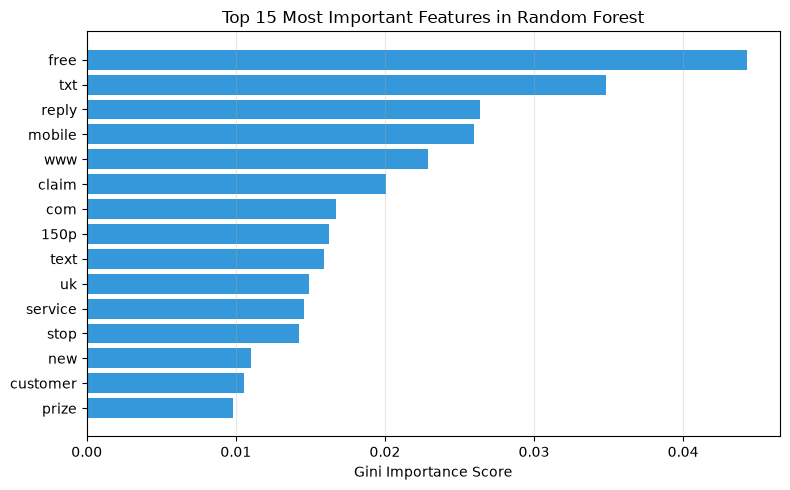

In [23]:
# Extract feature names and their importance scores from rf_pipeline
feature_names = rf_pipeline.named_steps['vectorizer'].get_feature_names_out()
importances = rf_pipeline.named_steps['rf_classifier'].feature_importances_

# Get top 15 features
top_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
top_df = top_df.sort_values(by='Importance', ascending=True).tail(15)

plt.figure(figsize=(8, 5))
plt.barh(top_df['Feature'], top_df['Importance'], color='#3498db')
plt.title('Top 15 Most Important Features in Random Forest')
plt.xlabel('Gini Importance Score')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

c:\Users\Raymond\OneDrive\Mga Dokumento\machine-learning\.venv\Lib\site-packages\sklearn\utils\_plotting.py:193: FutureWarning: `**kwargs` is deprecated and will be removed in 1.11. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(
c:\Users\Raymond\OneDrive\Mga Dokumento\machine-learning\.venv\Lib\site-packages\sklearn\utils\_plotting.py:193: FutureWarning: `**kwargs` is deprecated and will be removed in 1.11. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(
c:\Users\Raymond\OneDrive\Mga Dokumento\machine-learning\.venv\Lib\site-packages\sklearn\utils\_plotting.py:193: FutureWarning: `**kwargs` is deprecated and will be removed in 1.11. Pass all matplotlib arguments to `curve_kwargs` as a dictionary instead.
  warnings.warn(


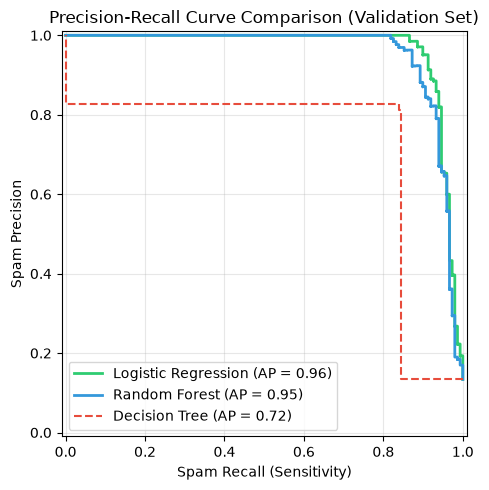

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

PrecisionRecallDisplay.from_estimator(
    logistic_pipeline, X_valid, y_valid, name="Logistic Regression", ax=ax, color="#2ecc71", linewidth=2
)
PrecisionRecallDisplay.from_estimator(
    rf_pipeline, X_valid, y_valid, name="Random Forest", ax=ax, color="#3498db", linewidth=2
)
PrecisionRecallDisplay.from_estimator(
    tree_pipeline, X_valid, y_valid, name="Decision Tree", ax=ax, color="#e74c3c", linestyle="--"
)

ax.set_title("Precision-Recall Curve Comparison (Validation Set)")
ax.set_xlabel("Spam Recall (Sensitivity)")
ax.set_ylabel("Spam Precision")
ax.grid(alpha=0.3)
plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

#### AUC for Model Selection

• AUC or Area Under the Curve represents the trade-off between Recall and Precision. The most ideal spot is a high Precision and high Recall. Or in our case, a perfect Precision while still maintaining good Recall.

• From the graph above, we can see that Logistic Regression won over Random Forests. This is because AUC tests out different thresholds in order to draw the curve. 


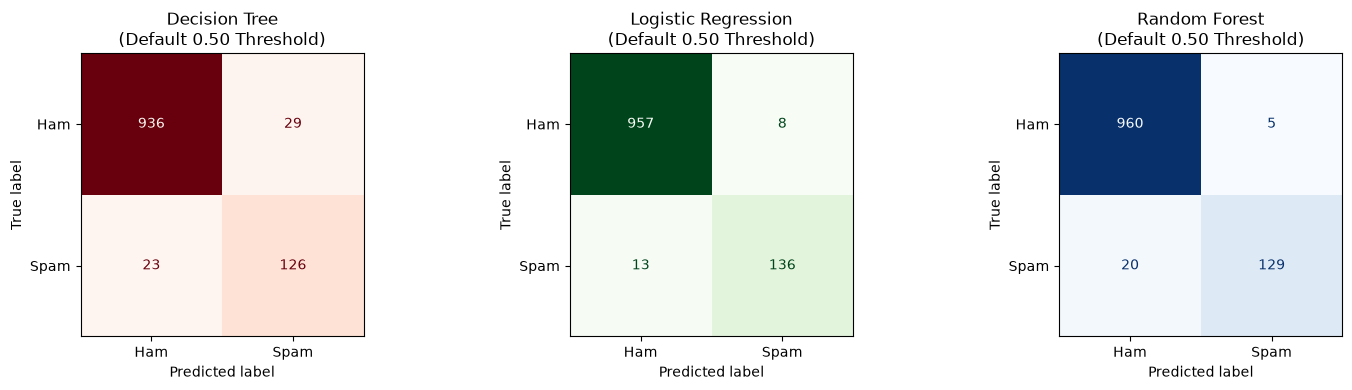

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

models = [
    ("Decision Tree", tree_predictions, "Reds"),
    ("Logistic Regression", log_predictions, "Greens"),
    ("Random Forest", rf_predictions, "Blues")
]

for ax, (name, preds, cmap) in zip(axes, models):
    ConfusionMatrixDisplay.from_predictions(
        y_valid, preds, 
        display_labels=['Ham', 'Spam'], 
        cmap=cmap, 
         colorbar=False, 
        ax=ax
    )
    ax.set_title(f"{name}\n(Default 0.50 Threshold)")

plt.tight_layout()
plt.show()

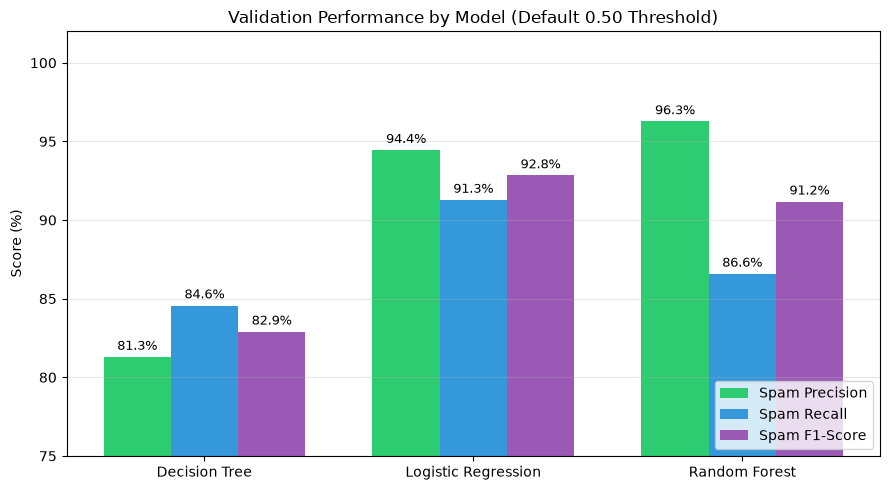

In [22]:
models = ['Decision Tree', 'Logistic Regression', 'Random Forest']
preds_list = [tree_predictions, log_predictions, rf_predictions]

precisions = [precision_score(y_valid, p) * 100 for p in preds_list]
recalls = [recall_score(y_valid, p) * 100 for p in preds_list]
f1s = [f1_score(y_valid, p) * 100 for p in preds_list]

x = np.arange(len(models))
width = 0.25

fig, ax = plt.subplots(figsize=(9, 5))
rects1 = ax.bar(x - width, precisions, width, label='Spam Precision', color='#2ecc71')
rects2 = ax.bar(x, recalls, width, label='Spam Recall', color='#3498db')
rects3 = ax.bar(x + width, f1s, width, label='Spam F1-Score', color='#9b59b6')

ax.set_ylabel('Score (%)')
ax.set_title('Validation Performance by Model (Default 0.50 Threshold)')
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylim(75, 102)  # Zoom in on the 75% - 100% range to highlight differences
ax.legend(loc='lower right')
ax.grid(axis='y', alpha=0.3)

# Add exact percentages on top of each bar
for rect in [rects1, rects2, rects3]:
    ax.bar_label(rect, fmt='%.1f%%', padding=3, fontsize=9)

plt.tight_layout()
plt.show()

#### 4. Threshold Tuning: Pushing Precision to the Ceiling

• Initially **Random Forests** won over **Logistic Regression**, with a baseline *threshold of 0.50*, narrowly beating LogisticRegression's Spam Precision score of 94.44% by 96.27% for Random Forests.

• However, the model selection did not just end there. It just showed that Random Forests is a competitive model. After tuning the thresholds for Random Forests' and Logistic Regression's Precision score to hit 100%, **Logistic Regression came up as the winner as while both hit 100% Precision score, Logistic Regression also had a higher Recall score of 86.58%**.

• The reason for this is that Logistic Regression takes in account of all the features' weight when computing their score in the sigmoid function. Hence why obvious spam messages can score really high (like 0.80 to even 0.90+). While less obvious spam messages, or ham messages for example, have a huge gap to overcome to even be labeled as a 'spam'.

• Random Forests on the other hand, only obtains a random sample of those features across multiple decision trees. Which means there is a chance that some trees won't even get the spam words and automatically default to voting it as a ham. And because less trees vote—in this case a spam sample—that it **is** a spam sample, the predicted probability/confidence of the model when it comes to labelling whether it is spam or ham gets lower. Which is why as soon as I raised the threshold higher to tune for Precision, a bunch of false negatives appear since they don't meet that threshold as much as Logistic Regression does.


In [12]:
def evaluate_thresholds(pipeline, X, y, model_name, thresholds=[0.50, 0.60, 0.70, 0.75, 0.80, 0.85, 0.90]):
    # Get probability of class 1 (Spam)
    spam_probs = pipeline.predict_proba(X)[:, 1]
    
    records = []
    for threshold in thresholds:
        preds = (spam_probs >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y, preds).ravel()
        
        prec = precision_score(y, preds, zero_division=0)
        rec = recall_score(y, preds, zero_division=0)
        f1 = f1_score(y, preds, zero_division=0)
        
        records.append({
            'Model': model_name,
            'Threshold': f"{threshold:.2f}",
            'Spam Precision': f"{prec * 100:.2f}%",
            'Spam Recall': f"{rec * 100:.2f}%",
            'F1-Score': f"{f1 * 100:.2f}%",
            'False Positives (Ham in Spam)': fp,
            'False Negatives (Spam in Inbox)': fn
        })
        
    return pd.DataFrame(records)

# Run threshold sweep for both models
df_log_thresh = evaluate_thresholds(logistic_pipeline, X_valid, y_valid, 'Logistic Regression')
df_rf_thresh = evaluate_thresholds(rf_pipeline, X_valid, y_valid, 'Random Forest')

# Combine and display results
threshold_report = pd.concat([df_log_thresh, df_rf_thresh], ignore_index=True)
display(threshold_report)

,Model,Threshold,Spam Precision,Spam Recall,F1-Score,False Positives (Ham in Spam),False Negatives (Spam in Inbox)
0,Logistic Regression,0.50,94.44%,91.28%,92.83%,8,13
1,Logistic Regression,0.60,97.08%,89.26%,93.01%,4,16
2,Logistic Regression,0.70,99.23%,86.58%,92.47%,1,20
3,Logistic Regression,0.75,100.00%,86.58%,92.81%,0,20
4,Logistic Regression,0.80,100.00%,85.23%,92.03%,0,22
5,Logistic Regression,0.85,100.00%,83.89%,91.24%,0,24
6,Logistic Regression,0.90,100.00%,82.55%,90.44%,0,26
7,Random Forest,0.50,96.27%,86.58%,91.17%,5,20
8,Random Forest,0.60,100.00%,81.21%,89.63%,0,28
9,Random Forest,0.70,100.00%,77.18%,87.12%,0,34


In [13]:
thresh_log_model = FixedThresholdClassifier(
    estimator=logistic_pipeline, 
    threshold=0.75
)

thresh_log_model.fit(X_train, y_train)

,"estimator estimator: estimator instanceThe binary classifier, fitted or not, for which we want to optimizethe decision threshold used during `predict`.",Pipeline(step...m_state=42))])
,"threshold threshold: {""auto""} or float, default=""auto""The decision threshold to use when converting posterior probability estimates(i.e. output of `predict_proba`) or decision scores (i.e. output of`decision_function`) into a class label. When `""auto""`, the threshold is setto 0.5 if `predict_proba` is used as `response_method`, otherwise it is set to0 (i.e. the default threshold for `decision_function`).",0.75
,"pos_label pos_label: int, float, bool or str, default=NoneThe label of the positive class. Used to process the output of the`response_method` method. When `pos_label=None`, if `y_true` is in `{-1, 1}` or`{0, 1}`, `pos_label` is set to 1, otherwise an error will be raised.",None
,"response_method response_method: {""auto"", ""decision_function"", ""predict_proba""}, default=""auto""Methods by the classifier `estimator` corresponding to thedecision function for which we want to find a threshold. It can be:* if `""auto""`, it will try to invoke `""predict_proba""` or `""decision_function""` in that order.* otherwise, one of `""predict_proba""` or `""decision_function""`. If the method is not implemented by the classifier, it will raise an error.",'auto'
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The class labels.","ndarray[int64](2,)","[0,1]"
estimator_ estimator_: estimator instanceThe fitted classifier used when predicting.,Pipeline,Pipeline(step...m_state=42))])
,"stop_words stop_words: {'english'}, list, default=NoneIf a string, it is passed to _check_stop_list and the appropriate stoplist is returned. 'english' is currently the only supported stringvalue.There are several known issues with 'english' and you shouldconsider an alternative (see :ref:`stop_words`).If a list, that list is assumed to contain stop words, all of whichwill be removed from the resulting tokens.Only applies if ``analyzer == 'word'``.If None, no stop words will be used. In this case, setting `max_df`to a higher value, such as in the range (0.7, 1.0), can automatically detectand filter stop words based on intra corpus document frequency of terms.",'english'
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",2
,"max_features max_features: int, default=NoneIf not None, build a vocabulary that only consider the top`max_features` ordered by term frequency across the corpus.Otherwise, all features are used.This parameter is ignored if vocabulary is not None.",3000



#### 5. Final Test Set Evaluation & Real-World Stress Testing

• To compare the scores of the default and optimized threshold, I outputted both confusion matrix scores and classification reports. 

• For the Spam Precision score, the **optimized wins over with 95.04% accuracy** with 7 false positives compared to the default threshold of 12 false positives.

• To stress test, I tested a new random set of emails to the model. Only the third sample, 'Congratulations! You have won a $1000 gift card. Click here to claim.' was flagged as spam. Though, the sample 1 and 5 were also spam. It was not flagged as spam due to the optimization of Precision requiring a larger confidence (score) to be labeled as spam. On the brighter side, the Ham emails we're not even close when it comes to being flagged as spam. Which is the exact reason why we optimized for Precision.

In [14]:
# 1. Default 0.50 threshold predictions on Test Set
test_preds_default = logistic_pipeline.predict(X_test)

# 2. Optimized 0.75 threshold predictions on Test Set
test_probs = logistic_pipeline.predict_proba(X_test)[:, 1]
test_preds_optimized = (test_probs >= 0.75).astype(int)

print("=== TEST SET: DEFAULT THRESHOLD (0.50) ===")
print(classification_report(y_test, test_preds_default, target_names=['Ham', 'Spam'], digits=4))
tn_d, fp_d, fn_d, tp_d = confusion_matrix(y_test, test_preds_default).ravel()
print(f"False Positives (Ham in Spam): {fp_d} | False Negatives (Spam in Inbox): {fn_d}\n")

print("=== TEST SET: PRECISION-OPTIMIZED (0.75) ===")
print(classification_report(y_test, test_preds_optimized, target_names=['Ham', 'Spam'], digits=4))
tn_o, fp_o, fn_o, tp_o = confusion_matrix(y_test, test_preds_optimized).ravel()
print(f"False Positives (Ham in Spam): {fp_o} | False Negatives (Spam in Inbox): {fn_o}")

=== TEST SET: DEFAULT THRESHOLD (0.50) ===
              precision    recall  f1-score   support

         Ham     0.9906    0.9876    0.9891       965
        Spam     0.9216    0.9400    0.9307       150

    accuracy                         0.9812      1115
   macro avg     0.9561    0.9638    0.9599      1115
weighted avg     0.9814    0.9812    0.9812      1115

False Positives (Ham in Spam): 12 | False Negatives (Spam in Inbox): 9

=== TEST SET: PRECISION-OPTIMIZED (0.75) ===
              precision    recall  f1-score   support

         Ham     0.9836    0.9927    0.9881       965
        Spam     0.9504    0.8933    0.9210       150

    accuracy                         0.9794      1115
   macro avg     0.9670    0.9430    0.9546      1115
weighted avg     0.9791    0.9794    0.9791      1115

False Positives (Ham in Spam): 7 | False Negatives (Spam in Inbox): 16


In [15]:
sample_emails = [
    'GET YOUR FREE VOUCHER NOW!', # Spam
    'Hey, are we still on for lunch tomorrow?', # Ham
    'Congratulations! You have won a $1000 gift card. Click here to claim.', # Spam
    'Reminder: Your appointment is scheduled for 3 PM today.', # Ham
    'Limited time offer! Buy one, get one free on all items.' # Spam
     ]

print(thresh_log_model.predict(sample_emails))
print(thresh_log_model.predict_proba(sample_emails)[:, 1])


[0 0 1 0 0]
[0.67340701 0.0057331  0.97347279 0.06182817 0.46667046]
